In [ ]:
import glob, os, random
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# --- пути (подрежь под себя) ---
BASE_WEIGHTS  = "/home/fedosdan2/Study/EdgeChess-AI/CV_3D/weights/best_3d_detection.pt"
FT_WEIGHTS    = "/home/fedosdan2/Study/EdgeChess-AI/runs/detect/CV_3D/runs/3d_finetune_synthetic/weights/best.pt"
SCRAT_WEIGHTS = "/home/fedosdan2/Study/EdgeChess-AI/runs/detect/CV_3D/runs/3d_from_scratch/weights/best.pt"
SCRAT_WEIGHTS_2 = "/home/fedosdan2/Study/EdgeChess-AI/CV_3D/weights/best_new_scratch.pt"
DATA_YAML     = "/home/fedosdan2/Study/EdgeChess-AI/CV_3D/synthetic-demo-aug/data.yaml"
TEST_IMAGES   = "/home/fedosdan2/Study/EdgeChess-AI/CV_3D/synthetic-demo-aug/test/images"

CONF = 0.25          # низкий порог, чтобы видеть и слабые детекции углов
N_SAMPLES = 4

# порядок классов = как в модели (12 фигур + 4 угла)
COLORS = {
    0:(200,255,200), 1:(255,255,255), 2:(100,255,100), 3:(0,255,100), 4:(0,150,0), 5:(0,200,0),
    6:(200,200,255), 7:(0,0,255),     8:(100,100,255), 9:(100,100,200),10:(0,0,150),11:(0,0,200),
    12:(255,255,0),  13:(255,128,0),  14:(128,0,255),  15:(0,255,128),  # углы
}
CORNER_IDS = {12,13,14,15}

# 4 случайных тестовых кадра
imgs = sorted(glob.glob(os.path.join(TEST_IMAGES, "*.*")))
imgs = [p for p in imgs if p.lower().endswith((".jpg",".jpeg",".png"))]
random.seed(42); random.shuffle(imgs)
sample_imgs = imgs[:N_SAMPLES]
print("Тестируем на:", [os.path.basename(p) for p in sample_imgs])

Тестируем на: ['position_0011_view_01.png', 'position_0009_view_01.png', 'position_0011_view_00.png', 'position_0022_view_00.png']


In [2]:
def draw(result, names):
    """Рисует bbox'ы вручную: фигуры тонко, углы жирно + крестик в центре."""
    img = result.orig_img.copy()                      # BGR
    h, w = img.shape[:2]
    boxes = result.boxes
    if boxes is None or len(boxes) == 0:
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    xywhn = boxes.xywhn.cpu().numpy()
    cls   = boxes.cls.cpu().numpy().astype(int)
    conf  = boxes.conf.cpu().numpy()

    for (xc,yc,bw,bh), c, cf in zip(xywhn, cls, conf):
        x1,y1 = int((xc-bw/2)*w), int((yc-bh/2)*h)
        x2,y2 = int((xc+bw/2)*w), int((yc+bh/2)*h)
        col = COLORS.get(int(c),(128,128,128))
        is_corner = int(c) in CORNER_IDS
        thick = 4 if is_corner else 2
        cv2.rectangle(img,(x1,y1),(x2,y2),col,thick)
        if is_corner:                                 # маркер точно в центр угла
            cv2.drawMarker(img,(int(xc*w),int(yc*h)),col,cv2.MARKER_CROSS,24,3)
        label = f"{names.get(int(c),'?')} {cf:.2f}"
        (tw,th),bl = cv2.getTextSize(label,cv2.FONT_HERSHEY_SIMPLEX,0.45,1)
        cv2.rectangle(img,(x1,y1-th-bl-2),(x1+tw,y1),col,-1)
        cv2.putText(img,label,(x1,y1-bl-2),cv2.FONT_HERSHEY_SIMPLEX,0.45,(0,0,0),1)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)       # -> RGB для matplotlib

✅ BASE: /home/fedosdan2/Study/EdgeChess-AI/CV_3D/weights/best_3d_detection.pt
✅ FINETUNED: /home/fedosdan2/Study/EdgeChess-AI/runs/detect/CV_3D/runs/3d_finetune_synthetic/weights/best.pt
✅ SCRATCH: /home/fedosdan2/Study/EdgeChess-AI/runs/detect/CV_3D/runs/3d_from_scratch/weights/best.pt
✅ SCRATCH2: /home/fedosdan2/Study/EdgeChess-AI/runs/detect/CV_3D/runs/3d_from_scratch_v2/weights/best.pt


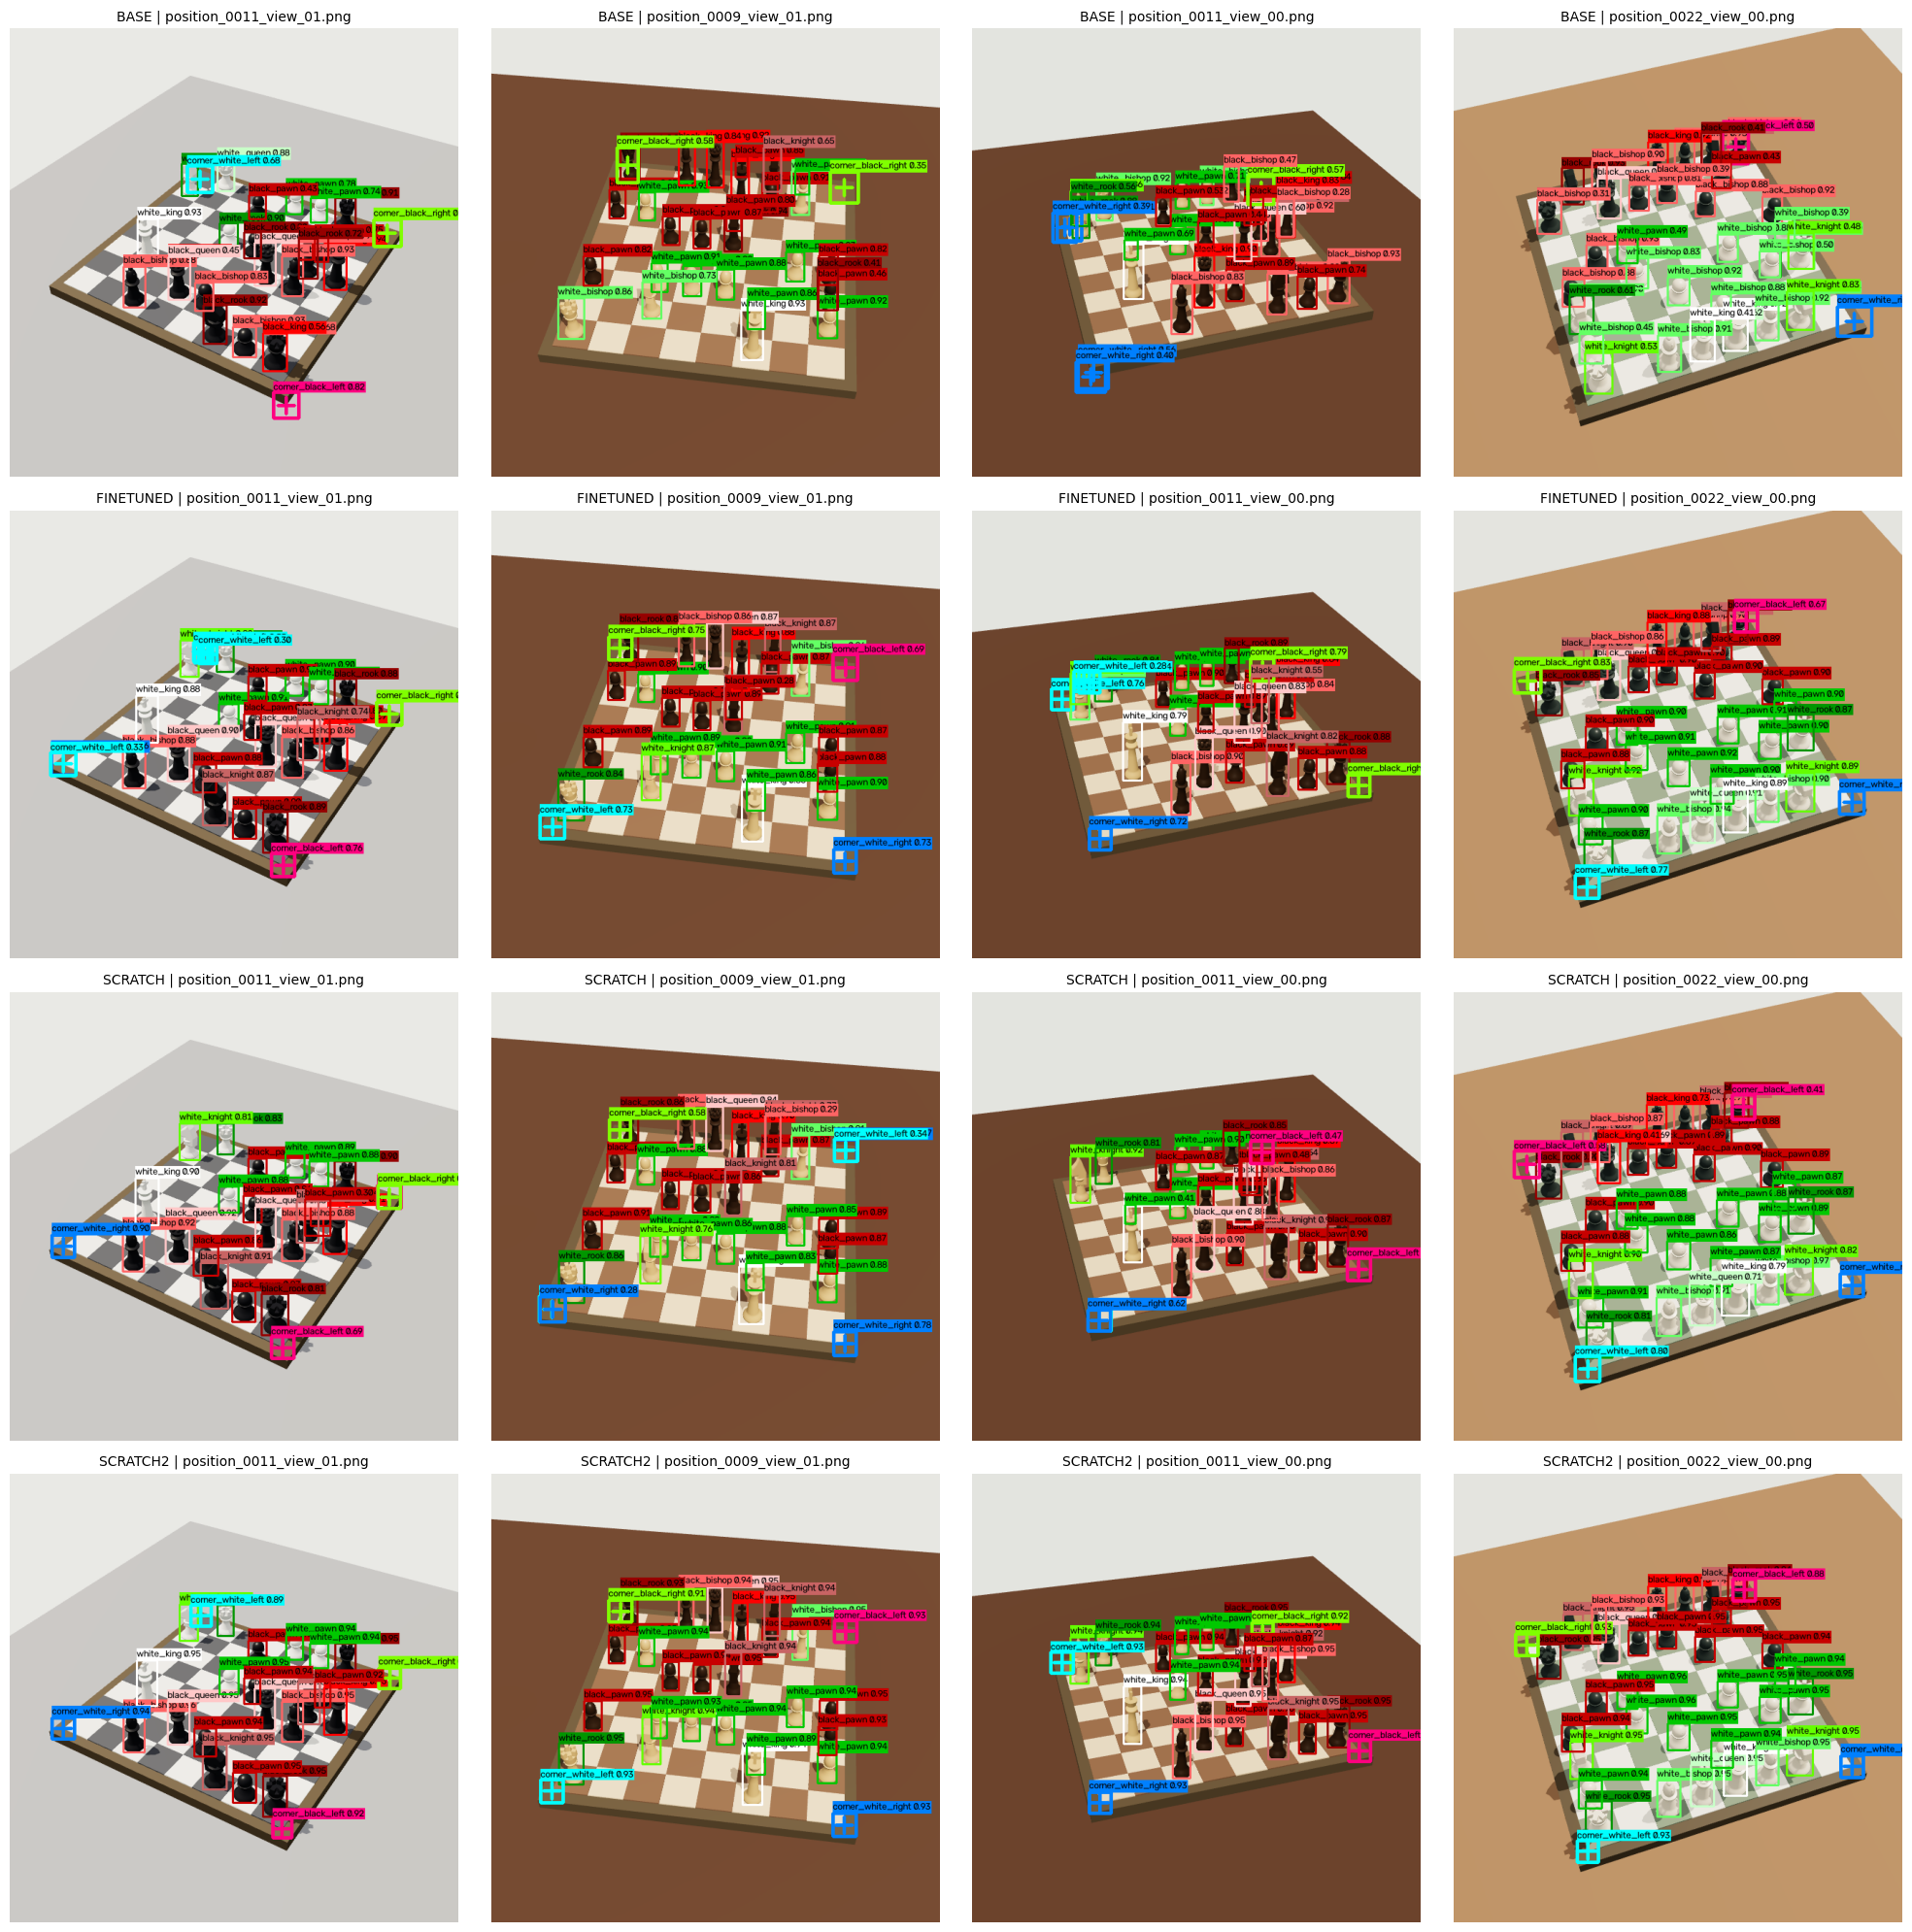

In [3]:
models = {}
for tag, path in [("BASE", BASE_WEIGHTS), ("FINETUNED", FT_WEIGHTS), ("SCRATCH", SCRAT_WEIGHTS), ("SCRATCH2", SCRAT_WEIGHTS_2)]:
    if Path(path).exists():
        models[tag] = YOLO(path)
        print(f"✅ {tag}: {path}")
    else:
        print(f"⚠️  {tag}: НЕ НАЙДЕНО {path} — пропускаю")

n_cols = len(sample_imgs)
fig, axes = plt.subplots(len(models), n_cols, figsize=(5*n_cols, 5*len(models)))
if len(models) == 1: axes = axes[None, :]

for r,(tag,m) in enumerate(models.items()):
    names = m.names
    for c,img_path in enumerate(sample_imgs):
        res = m.predict(img_path, conf=CONF, verbose=False)[0]
        axes[r,c].imshow(draw(res, names))
        axes[r,c].set_title(f"{tag} | {os.path.basename(img_path)}", fontsize=10)
        axes[r,c].axis("off")

plt.tight_layout(); plt.show()